# FlyRank ML Capstone — Intelligent Content Refresh Prioritization

**Lane:** Refresh / Content Opportunity Scoring  
**Research question:** Can historical content-performance signals help rank content records labelled as declining for manual review?

This capstone consolidates the work from Weeks 5–7. It reuses the Week 5 model comparison and Week 4 baseline, applies the Week 6 leakage and grouped-validation discipline, and builds on the Week 7 human-reviewed action playbook.

**Safety:** This notebook does not display raw rows or client/content IDs. It writes only aggregate charts and metrics for the paper; the row-level queue is a local, gitignored artifact. Do not add credentials, private exports, client names, domains, URLs, titles, or queries to public outputs.


## 1. Question and decision

The decision is **which anonymized content records should be reviewed first**, given limited editorial capacity. The model target is the dataset's observed `trend_direction == "down"` label. It is a proxy label from the supplied snapshot, not a verified future-decline label.

Success means measuring ranking quality against the existing Week 4 rule baseline on the same client-grouped held-out test records, then generating a transparent queue with reason codes and human-review checks.


## 2. Data and public-safe handling

The notebook uses the approved anonymized starter dataset referenced by this repository. The dataset is loaded from the repository path when available, otherwise from its configured public starter URL. This notebook intentionally avoids printing example rows or identifiers.

Historical-window reconstruction assumes the 90-day totals equal the sum of the latest 30-day, previous 30-day, and 61–90-day windows. Incomplete or negative reconstructions are treated as missing. This assumption must remain documented because the underlying source timestamps are not independently verified here.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
)

RANDOM_STATE = 42
DATA_REL = Path("data/raw/content_refresh_anonymized.csv")
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "Viditp25/flyrank-intern-/main/"
    "data/raw/content_refresh_anonymized.csv"
)


def find_repo_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / DATA_REL).is_file():
            return candidate
    return None


repo_root = find_repo_root()
data_source = str(repo_root / DATA_REL) if repo_root else DATA_URL
df = pd.read_csv(data_source)

required_columns = [
    "client_id", "content_id", "trend_direction", "days_since_last_update",
    "impressions_90d", "impressions_last_30d", "impressions_prev_30d",
    "clicks_90d", "clicks_last_30d", "clicks_prev_30d",
    "sessions_90d", "sessions_last_30d", "sessions_prev_30d",
]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {missing_columns}. "
        "The Week 4 baseline requires days_since_last_update; verify the exact source field if absent."
    )

print("Dataset loaded from the approved repository path or configured public starter URL.")
print(f"Rows: {len(df):,} | Columns: {len(df.columns):,}")
print("Schema columns:", len(df.columns))
print("No row-level records or identifiers are displayed in this capstone notebook.")

labels = df["trend_direction"].astype("string").str.strip().str.lower()
print("Observed trend_direction labels:")
display(labels.value_counts(dropna=False).to_frame("rows"))

valid_labels = {"down", "stable", "up", "new", "flat"}
invalid_labels = labels.isna() | ~labels.isin(valid_labels)
if invalid_labels.any():
    raise ValueError(
        "Missing or unexpected target labels found:\n"
        f"{labels[invalid_labels].value_counts(dropna=False)}"
    )

df["target"] = labels.eq("down").astype(int)
if df["target"].nunique() != 2:
    raise ValueError("The binary target must contain both classes.")

print("Binary target distribution:")
display(df["target"].value_counts().sort_index().rename_axis("target").to_frame("rows"))
print(f"Observed decline-label rate: {df['target'].mean():.2%}")

Dataset loaded from the approved repository path or configured public starter URL.
Rows: 30,000 | Columns: 44
Schema columns: 44
No row-level records or identifiers are displayed in this capstone notebook.
Observed trend_direction labels:


,rows
trend_direction,
down,16262
stable,5962
up,4388
new,2236
flat,1152


Binary target distribution:


,rows
target,
0,13738
1,16262


Observed decline-label rate: 54.21%


### Historical-window reconstruction audit

The next cell reproduces the Week 5 reconstruction and reports only aggregate counts—not page-level data.


In [2]:
audit_rows = []
for metric in ["impressions", "clicks", "sessions"]:
    total = pd.to_numeric(df[f"{metric}_90d"], errors="coerce")
    last = pd.to_numeric(df[f"{metric}_last_30d"], errors="coerce")
    previous = pd.to_numeric(df[f"{metric}_prev_30d"], errors="coerce")
    older = total - last - previous
    missing_source = total.isna() | last.isna() | previous.isna()
    negative_reconstruction = older.lt(0) & ~missing_source
    invalid_reconstruction = missing_source | negative_reconstruction

    df[f"{metric}_days_61_90"] = older.mask(invalid_reconstruction)
    audit_rows.append({
        "Metric": metric,
        "Rows": len(df),
        "Missing source rows": int(missing_source.sum()),
        "Negative reconstructed rows": int(negative_reconstruction.sum()),
        "Valid reconstructed rows": int((~invalid_reconstruction).sum()),
    })

audit_table = pd.DataFrame(audit_rows)
print("Historical reconstruction audit:")
display(audit_table)

# Alias used by the original Week 4 baseline.
df["impr_days_61_90"] = df["impressions_days_61_90"]

Historical reconstruction audit:


,Metric,Rows,Missing source rows,Negative reconstructed rows,Valid reconstructed rows
0,impressions,30000,0,0,30000
1,clicks,30000,0,0,30000
2,sessions,30000,0,0,30000


## 3. Methodology: features, label, baseline, and validation

- **Label:** `target = 1` when `trend_direction == "down"`; accepted non-down labels are `0`.
- **Features:** selected historical performance windows and content metadata.
- **Excluded:** client/content IDs as predictors, `trend_direction`, `trend_pct`, the target, latest 30-day metrics, and 90-day totals.
- **Preprocessing:** imputation, scaling, and one-hot encoding occur inside the sklearn pipeline, fitted on training data only.
- **Validation:** fixed-seed 80/20 `GroupShuffleSplit` by client, ensuring zero client overlap.
- **Models:** Decision Tree, Logistic Regression, Random Forest.
- **Baseline:** Week 4 rule requiring `days_since_last_update >= 91` and `impr_days_61_90 >= 100`, ranked by reconstructed historical impressions.

This is client-grouped validation, not time-forward validation. Feature timestamps and availability at decision time still need confirmation.


In [3]:
# Keep rows with both grouping ID and content ID.
model_df = df.loc[df["client_id"].notna() & df["content_id"].notna()].copy()

# Build preceding-window totals and derived historical features.
for metric in ["impressions", "clicks", "sessions"]:
    previous = pd.to_numeric(model_df[f"{metric}_prev_30d"], errors="coerce")
    older = pd.to_numeric(model_df[f"{metric}_days_61_90"], errors="coerce")
    model_df[f"{metric}_pre"] = previous + older

impressions_pre = pd.to_numeric(model_df["impressions_pre"], errors="coerce")
clicks_pre = pd.to_numeric(model_df["clicks_pre"], errors="coerce")
model_df["ctr_pre"] = clicks_pre / impressions_pre.replace(0, np.nan)

older_impressions = pd.to_numeric(model_df["impressions_days_61_90"], errors="coerce")
previous_impressions = pd.to_numeric(model_df["impressions_prev_30d"], errors="coerce")
model_df["prior_momentum_pct"] = (
    (previous_impressions - older_impressions)
    / older_impressions.replace(0, np.nan)
) * 100

log_source_columns = [
    "impressions_days_61_90", "clicks_days_61_90", "sessions_days_61_90",
    "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d",
    "impressions_pre", "clicks_pre", "sessions_pre",
]
for col in log_source_columns:
    values = pd.to_numeric(model_df[col], errors="coerce")
    model_df[f"log1p_{col}"] = np.log1p(values.where(values >= 0))

numeric_candidates = [
    "search_volume", "competition", "cpc", "word_count", "char_count",
    "impressions_days_61_90", "clicks_days_61_90", "sessions_days_61_90",
    "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d",
    "impressions_pre", "clicks_pre", "sessions_pre", "ctr_pre", "prior_momentum_pct",
    "log1p_impressions_days_61_90", "log1p_clicks_days_61_90", "log1p_sessions_days_61_90",
    "log1p_impressions_prev_30d", "log1p_clicks_prev_30d", "log1p_sessions_prev_30d",
    "log1p_impressions_pre", "log1p_clicks_pre", "log1p_sessions_pre",
]
categorical_candidates = ["competition_level", "content_type", "main_intent", "word_count_tier"]

forbidden_features = {
    "client_id", "content_id", "trend_direction", "target", "trend_pct",
    "impressions_last_30d", "clicks_last_30d", "sessions_last_30d",
    "impressions_90d", "clicks_90d", "sessions_90d",
}
numeric_features = [
    col for col in numeric_candidates
    if col in model_df.columns and col not in forbidden_features
]
categorical_features = [
    col for col in categorical_candidates
    if col in model_df.columns and col not in forbidden_features
]

for col in numeric_features:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
numeric_features = [col for col in numeric_features if model_df[col].notna().any()]
feature_cols = numeric_features + categorical_features
if not feature_cols:
    raise ValueError("No eligible predictor columns were found. Check the dataset schema.")

X = model_df[feature_cols].copy()
y = model_df["target"].astype(int).copy()
groups = model_df["client_id"].copy()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
transformers = []
if numeric_features:
    transformers.append(("num", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_pipeline, categorical_features))
pre = ColumnTransformer(transformers=transformers, remainder="drop")

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

metadata_cols = [
    col for col in ["content_id", "client_id", "main_intent", "word_count_tier"]
    if col in model_df.columns
]
train_meta = model_df.iloc[train_idx][metadata_cols].copy()
test_meta = model_df.iloc[test_idx][metadata_cols].copy()
train_clients = set(train_meta["client_id"].dropna())
test_clients = set(test_meta["client_id"].dropna())
client_overlap = train_clients.intersection(test_clients)

assert not client_overlap, f"Client overlap found: {len(client_overlap)}"
assert y_train.nunique() == 2 and y_test.nunique() == 2, "Both classes must occur in train and test."
assert len(y_test) >= 100, "At least 100 test rows are required for Precision@100."

print(f"Rows used: {len(model_df):,}")
print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print(f"Training clients: {len(train_clients):,} | Test clients: {len(test_clients):,}")
print(f"Client overlap: {len(client_overlap)}")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Training target distribution:")
display(y_train.value_counts().sort_index().rename_axis("target").to_frame("rows"))
print("Test target distribution:")
display(y_test.value_counts().sort_index().rename_axis("target").to_frame("rows"))

Rows used: 30,000
Training rows: 23,837 | Test rows: 6,163
Training clients: 25 | Test clients: 7
Client overlap: 0
Numeric features: ['search_volume', 'competition', 'cpc', 'word_count', 'char_count', 'impressions_days_61_90', 'clicks_days_61_90', 'sessions_days_61_90', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'impressions_pre', 'clicks_pre', 'sessions_pre', 'ctr_pre', 'prior_momentum_pct', 'log1p_impressions_days_61_90', 'log1p_clicks_days_61_90', 'log1p_sessions_days_61_90', 'log1p_impressions_prev_30d', 'log1p_clicks_prev_30d', 'log1p_sessions_prev_30d', 'log1p_impressions_pre', 'log1p_clicks_pre', 'log1p_sessions_pre']
Categorical features: ['competition_level', 'content_type', 'main_intent', 'word_count_tier']
Training target distribution:


,rows
target,
0,10724
1,13113


Test target distribution:


,rows
target,
0,3014
1,3149


### Model comparison against the Week 4 baseline

All four methods use the same held-out rows and labels. Precision@K is relevant when review capacity is limited; Average Precision and ROC-AUC measure ranking/discrimination; Brier Score is reported only for probabilistic classifiers.


In [4]:
# Validate exact inputs required by the Week 4 rule.
baseline_required = ["days_since_last_update", "impr_days_61_90"]
missing_baseline_columns = [col for col in baseline_required if col not in model_df.columns]
if missing_baseline_columns:
    raise KeyError(
        "Cannot reproduce the Week 4 baseline because these exact columns are missing: "
        f"{missing_baseline_columns}. Check the Week 4 notebook and dataset schema; "
        "do not replace them with guessed aliases."
    )

# Precision@K for a ranked list; tied scores are resolved deterministically by content ID.
def precision_at_k(y_true, scores, content_ids, ks=(10, 20, 50, 100)):
    ranked = pd.DataFrame({
        "actual": np.asarray(y_true, dtype=int),
        "score": np.asarray(scores, dtype=float),
        "content_id": np.asarray(content_ids).astype(str),
    }).sort_values(["score", "content_id"], ascending=[False, True], kind="mergesort")
    if len(ranked) < max(ks):
        raise ValueError(f"At least {max(ks)} test rows are required; got {len(ranked)}.")
    return {f"Precision@{k}": float(ranked["actual"].iloc[:k].mean()) for k in ks}


def evaluate_classifier(y_true, probabilities, content_ids):
    y_array = np.asarray(y_true, dtype=int)
    probability_array = np.asarray(probabilities, dtype=float)
    if len(y_array) != len(probability_array):
        raise ValueError("Labels and predicted probabilities have different lengths.")
    if not np.isfinite(probability_array).all() or not ((probability_array >= 0) & (probability_array <= 1)).all():
        raise ValueError("Predicted probabilities must be finite and between 0 and 1.")
    result = precision_at_k(y_array, probability_array, content_ids)
    result["ROC-AUC"] = roc_auc_score(y_array, probability_array)
    result["Average Precision"] = average_precision_score(y_array, probability_array)
    result["Brier Score"] = brier_score_loss(y_array, probability_array)
    return result


models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Logistic Regression": LogisticRegression(
        C=0.1, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=8, min_samples_leaf=20,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
}

fitted = {}
predictions = {}
model_rows = []
for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(pre)),
        ("model", clone(estimator)),
    ])
    pipeline.fit(X_train, y_train)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    fitted[name] = pipeline
    predictions[name] = probabilities
    model_rows.append({
        "Method": name,
        **evaluate_classifier(y_test, probabilities, test_meta["content_id"]),
    })

# Apply the original Week 4 eligibility rule to the test rows only.
baseline_test = model_df.iloc[test_idx].copy()
baseline_age = pd.to_numeric(baseline_test["days_since_last_update"], errors="coerce")
baseline_impressions = pd.to_numeric(baseline_test["impr_days_61_90"], errors="coerce")
baseline_eligible = baseline_age.ge(91) & baseline_impressions.ge(100)
eligible_count = int(baseline_eligible.sum())
ks = (10, 20, 50, 100)

# Scores below every eligible score keep eligible pages ahead for full-test ranking metrics.
baseline_scores_all = np.where(
    baseline_eligible.to_numpy(),
    baseline_impressions.fillna(0).to_numpy(dtype=float),
    -1.0,
)

baseline_metrics = {}
eligible_ranked = pd.DataFrame({
    "actual": np.asarray(y_test, dtype=int)[baseline_eligible.to_numpy()],
    "score": baseline_impressions.loc[baseline_eligible].to_numpy(dtype=float),
    "content_id": test_meta.loc[baseline_eligible.to_numpy(), "content_id"].astype(str).to_numpy(),
}).sort_values(["score", "content_id"], ascending=[False, True], kind="mergesort")

for k in ks:
    if eligible_count >= k:
        baseline_metrics[f"Precision@{k}"] = float(eligible_ranked["actual"].iloc[:k].mean())
    else:
        baseline_metrics[f"Precision@{k}"] = np.nan

baseline_metrics["ROC-AUC"] = roc_auc_score(y_test, baseline_scores_all)
baseline_metrics["Average Precision"] = average_precision_score(y_test, baseline_scores_all)
baseline_metrics["Brier Score"] = np.nan
model_rows.append({"Method": "Week 4 Rule Baseline", **baseline_metrics})

comparison = pd.DataFrame(model_rows).set_index("Method")
comparison = comparison.sort_values("Average Precision", ascending=False, na_position="last")

print(f"Week 4 baseline eligible test pages: {eligible_count:,} / {len(y_test):,} ({eligible_count / len(y_test):.2%})")
print("Model vs Week 4 Rule Baseline:")
display(comparison.round(4))

# Validate comparison structure and values. Baseline Precision@K can be NA only when its eligible queue is too short.
expected_models = {"Decision Tree", "Logistic Regression", "Random Forest"}
expected_methods = expected_models | {"Week 4 Rule Baseline"}
assert set(comparison.index) == expected_methods
assert len(comparison) == 4
ranking_columns = ["Precision@10", "Precision@20", "Precision@50", "Precision@100", "ROC-AUC", "Average Precision"]
for method in expected_models:
    assert np.isfinite(comparison.loc[method, ranking_columns].to_numpy(dtype=float)).all()
    assert np.isfinite(comparison.loc[method, "Brier Score"])
assert np.isfinite(comparison.loc["Week 4 Rule Baseline", ["ROC-AUC", "Average Precision"]].to_numpy(dtype=float)).all()
assert pd.isna(comparison.loc["Week 4 Rule Baseline", "Brier Score"])
for k in ks:
    value = comparison.loc["Week 4 Rule Baseline", f"Precision@{k}"]
    assert (eligible_count >= k and np.isfinite(value)) or (eligible_count < k and pd.isna(value))

print("PASS: Three classifiers and the Week 4 rule were evaluated on the same held-out test rows.")

Week 4 baseline eligible test pages: 730 / 6,163 (11.84%)
Model vs Week 4 Rule Baseline:


,Precision@10,Precision@20,Precision@50,Precision@100,ROC-AUC,Average Precision,Brier Score
Method,,,,,,,
Random Forest,0.6,0.50,0.48,0.54,0.6581,0.6096,0.2204
Logistic Regression,0.8,0.75,0.66,0.66,0.6171,0.5988,0.2505
Decision Tree,1.0,0.65,0.66,0.65,0.6426,0.5975,0.2235
Week 4 Rule Baseline,0.3,0.25,0.38,0.34,0.4919,0.5028,NaN


PASS: Three classifiers and the Week 4 rule were evaluated on the same held-out test rows.


### Error analysis and interpretation

The 0.5 threshold is diagnostic only. The error examples use synthetic row labels and do not display client/content IDs. Logistic Regression coefficients are associations in the encoded feature space, not causal effects.


In [5]:
# 1. Inspect Logistic Regression coefficients.
lr = fitted["Logistic Regression"]
lr_probabilities = predictions["Logistic Regression"]
feature_names = lr.named_steps["preprocessor"].get_feature_names_out()
coefficients = lr.named_steps["model"].coef_[0]
assert len(feature_names) == len(coefficients)

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute coefficient": np.abs(coefficients),
}).sort_values("Absolute coefficient", ascending=False)
print("Top 15 Logistic Regression coefficients (by absolute magnitude):")
display(coefficient_table.head(15).round(4))

# 2. Classification errors at a diagnostic threshold of 0.5.
threshold = 0.5
errors = pd.DataFrame({"example": [f"test_example_{i+1:03d}" for i in range(len(y_test))]})
errors["actual"] = np.asarray(y_test, dtype=int)
errors["probability"] = np.asarray(lr_probabilities, dtype=float)
errors["predicted"] = (errors["probability"] >= threshold).astype(int)
errors["error_type"] = np.select(
    [
        (errors["actual"] == 1) & (errors["predicted"] == 0),
        (errors["actual"] == 0) & (errors["predicted"] == 1),
    ],
    ["False Negative", "False Positive"],
    default="Correct",
)
print("Classification outcome counts:")
display(errors["error_type"].value_counts().rename_axis("error_type").to_frame("count"))

false_positives = errors[errors["error_type"] == "False Positive"].sort_values("probability", ascending=False)
false_negatives = errors[errors["error_type"] == "False Negative"].sort_values("probability", ascending=True)
print("Highest-probability false positives:")
display(false_positives[["example", "actual", "probability"]].head(5))
print("Lowest-probability false negatives:")
display(false_negatives[["example", "actual", "probability"]].head(5))

# 3. Subgroup audit; small groups are omitted to avoid over-interpreting unstable estimates.
for col in ["main_intent", "word_count_tier"]:
    if col not in test_meta.columns:
        print(f"Subgroup audit skipped: {col} is unavailable.")
        continue
    subgroup = test_meta[[col]].copy().reset_index(drop=True)
    subgroup["actual"] = np.asarray(y_test, dtype=int)
    subgroup["predicted"] = errors["predicted"].to_numpy()
    subgroup["correct"] = (subgroup["actual"] == subgroup["predicted"]).astype(int)
    summary = (
        subgroup.groupby(col, dropna=False)
        .agg(N=("actual", "size"), decline_rate=("actual", "mean"), accuracy=("correct", "mean"))
        .reset_index()
    )
    summary = summary.loc[summary["N"] >= 30]
    print(f"Subgroup results for {col} (N >= 30):")
    display(summary.round(4))

# 4. Confusion matrix.
tn, fp, fn, tp = confusion_matrix(errors["actual"], errors["predicted"], labels=[0, 1]).ravel()
print("Confusion matrix counts at threshold 0.5:")
print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")
assert len(errors) == len(y_test)
assert (tn + fp + fn + tp) == len(y_test)
print("PASS: Error analysis completed and aligns with the held-out test labels.")

Top 15 Logistic Regression coefficients (by absolute magnitude):


,Feature,Coefficient,Absolute coefficient
22,num__log1p_impressions_pre,1.4970,1.4970
16,num__log1p_impressions_days_61_90,-0.8641,0.8641
41,cat__word_count_tier_Unknown,-0.8138,0.8138
23,num__log1p_clicks_pre,-0.7638,0.7638
19,num__log1p_impressions_prev_30d,0.7396,0.7396
21,num__log1p_sessions_prev_30d,-0.6474,0.6474
24,num__log1p_sessions_pre,0.4934,0.4934
37,cat__word_count_tier_1000-2000,0.4857,0.4857
32,cat__main_intent_Unknown,0.4374,0.4374
8,num__impressions_prev_30d,-0.3943,0.3943


Classification outcome counts:


,count
error_type,
Correct,3500
False Positive,1512
False Negative,1151


Highest-probability false positives:


...

Subgroup results for main_intent (N >= 30):


,main_intent,N,decline_rate,accuracy
0,commercial,986,0.5000,0.5680
1,informational,4000,0.4962,0.5605
3,transactional,1152,0.5729,0.5920


Subgroup results for word_count_tier (N >= 30):


,word_count_tier,N,decline_rate,accuracy
0,1000-2000,806,0.4404,0.5682
1,2000-3500,3863,0.5423,0.5713
2,3500+,409,0.4841,0.5721
3,NaN,1085,0.4618,0.5539


Confusion matrix counts at threshold 0.5:
True negatives:  1502
False positives: 1512
False negatives: 1151
True positives:  1998
PASS: Error analysis completed and aligns with the held-out test labels.


### Current-run conclusion

The following conclusions are generated from the metrics computed in this execution. Do not copy old numbers from previous runs.


In [6]:
# Build a conclusion from the current run's comparison table (no hard-coded old metrics).
model_comparison = comparison.loc[["Decision Tree", "Logistic Regression", "Random Forest"]]
best_ap_model = model_comparison["Average Precision"].idxmax()
best_auc_model = model_comparison["ROC-AUC"].idxmax()
best_brier_model = model_comparison["Brier Score"].idxmin()

print("CONCLUSION — CURRENT NOTEBOOK RUN")
print(f"Highest Average Precision among classifiers: {best_ap_model} ({model_comparison.loc[best_ap_model, 'Average Precision']:.4f}).")
print(f"Highest ROC-AUC among classifiers: {best_auc_model} ({model_comparison.loc[best_auc_model, 'ROC-AUC']:.4f}).")
print(f"Lowest Brier Score among classifiers: {best_brier_model} ({model_comparison.loc[best_brier_model, 'Brier Score']:.4f}).")
for k in (10, 20, 50, 100):
    metric = f"Precision@{k}"
    best_model = model_comparison[metric].idxmax()
    best_value = model_comparison.loc[best_model, metric]
    print(f"Highest {metric} among classifiers: {best_model} ({best_value:.4f}).")

baseline = comparison.loc["Week 4 Rule Baseline"]
print(f"Week 4 baseline eligibility: {eligible_count} of {len(y_test)} test pages.")
for metric in ["Precision@10", "Precision@20", "Precision@50", "Precision@100", "ROC-AUC", "Average Precision"]:
    value = baseline[metric]
    if pd.isna(value):
        print(f"Week 4 baseline {metric}: unavailable (fewer than K eligible pages).")
    else:
        print(f"Week 4 baseline {metric}: {value:.4f}.")

print("Interpretation: choose a method based on the review capacity and the metric that matches the intended workflow. These results describe predictive performance on a client-grouped holdout, not causation. A later time-based evaluation and verification of predictor availability are needed before operational use.")

CONCLUSION — CURRENT NOTEBOOK RUN
Highest Average Precision among classifiers: Random Forest (0.6096).
Highest ROC-AUC among classifiers: Random Forest (0.6581).
Lowest Brier Score among classifiers: Random Forest (0.2204).
Highest Precision@10 among classifiers: Decision Tree (1.0000).
Highest Precision@20 among classifiers: Logistic Regression (0.7500).
Highest Precision@50 among classifiers: Decision Tree (0.6600).
Highest Precision@100 among classifiers: Logistic Regression (0.6600).
Week 4 baseline eligibility: 730 of 6163 test pages.
Week 4 baseline Precision@10: 0.3000.
Week 4 baseline Precision@20: 0.2500.
Week 4 baseline Precision@50: 0.3800.
Week 4 baseline Precision@100: 0.3400.
Week 4 baseline ROC-AUC: 0.4919.
Week 4 baseline Average Precision: 0.5028.
Interpretation: choose a method based on the review capacity and the metric that matches the intended workflow. These results describe predictive performance on a client-grouped holdout, not causation. A later time-based eval

## 4. Results

The comparison table above is the primary result. Interpret Precision@K alongside the held-out target base rate. A model's best score on one metric does not automatically make it the best operational choice; the relevant metric depends on review capacity and the cost of missed opportunities.

The Week 4 baseline's Precision@K may be unavailable when fewer than K test records meet its eligibility rule. This is a real limitation of the rule, not a value to fill in.


## 5. Limitations and honest framing

1. **Proxy label:** the model ranks an observed declining category; it does not predict a clean future-window outcome.
2. **Not time-forward:** the client-grouped holdout tests transfer to unseen clients, not performance on a later time period.
3. **Timestamp uncertainty:** the availability of metadata before the outcome period must be verified.
4. **Observational evidence:** the analysis cannot prove that a content refresh causes traffic growth or that the model has discovered Google's ranking algorithm.
5. **Operational risk:** scores are review-priority signals, not calibrated probabilities of refresh benefit. Human review is required before editorial or technical changes.
6. **Baseline constraints:** the Week 4 rule may return too few eligible records for some Precision@K values.


## 6. Ranked recommendations and reason codes

The queue uses five-fold client-grouped out-of-fold Logistic Regression scores for the observed declining label. It adds transparent reason codes and suggested actions, but no client/content identifiers. Scores are for relative review prioritization and must not be described as future predictions or calibrated refresh-benefit probabilities.


In [7]:

from sklearn.model_selection import GroupKFold, cross_val_predict

n_clients = groups.nunique()
if n_clients < 5:
    raise ValueError(
        f"Week 7 requires at least 5 distinct clients for grouped out-of-fold scoring; found {n_clients}."
    )

queue_pipeline = Pipeline([
    ("preprocessor", clone(pre)),
    ("model", LogisticRegression(
        C=0.1, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    )),
])
cv = GroupKFold(n_splits=5)
queue_scores = cross_val_predict(
    queue_pipeline, X, y, groups=groups, cv=cv, method="predict_proba"
)[:, 1]

assert len(queue_scores) == len(model_df)
assert np.isfinite(queue_scores).all()
assert ((queue_scores >= 0) & (queue_scores <= 1)).all()

momentum = pd.to_numeric(model_df["prior_momentum_pct"], errors="coerce")
prior_impressions = pd.to_numeric(model_df["impressions_pre"], errors="coerce")
word_count = pd.to_numeric(model_df.get("word_count", pd.Series(np.nan, index=model_df.index)), errors="coerce")
content_type = model_df.get("content_type", pd.Series("Unknown", index=model_df.index)).astype("string").fillna("Unknown").str.lower()
main_intent = model_df.get("main_intent", pd.Series("Unknown", index=model_df.index)).astype("string").fillna("Unknown").str.lower()

queue = pd.DataFrame({
    "queue_row_id": [f"Q{i:06d}" for i in range(1, len(model_df) + 1)],
    "review_priority_score": queue_scores,
})
queue["priority_band"] = pd.cut(
    queue["review_priority_score"],
    bins=[-np.inf, 0.35, 0.50, 0.70, np.inf],
    labels=["Routine", "Review", "High review", "Highest review"],
    right=False,
).astype(str)

reason_codes, actions, review_notes = [], [], []
for pos in range(len(model_df)):
    score = float(queue_scores[pos])
    mom = momentum.iloc[pos]
    impr = prior_impressions.iloc[pos]
    typ = content_type.iloc[pos]
    intent = main_intent.iloc[pos]

    low_evidence = pd.isna(impr) or impr < 100
    negative_momentum = pd.notna(mom) and mom <= -20
    positive_momentum = pd.notna(mom) and mom >= 20

    if low_evidence:
        reason_codes.append("LOW_EVIDENCE")
        actions.append("Gather more evidence; defer content changes")
        review_notes.append("Check data coverage, sample size, and recent history")
    elif negative_momentum and score >= 0.50:
        reason_codes.append("MOMENTUM_DOWN+HIGH_REVIEW_SCORE")
        actions.append("Investigate decline; consider targeted content/technical review")
        review_notes.append("Verify trend window, intent match, seasonality, and technical health")
    elif score >= 0.70:
        reason_codes.append("HIGH_REVIEW_SCORE")
        actions.append("Prioritize manual performance and intent review")
        review_notes.append("Score is not a forecast; compare with business value and context")
    elif (("informational" in intent or "article" in typ or "blog" in typ) and score >= 0.50):
        reason_codes.append("CONTENT_GAP_REVIEW")
        actions.append("Review intent coverage, accuracy, freshness, and missing subtopics")
        review_notes.append("Do not add length without a demonstrated user/search need")
    elif positive_momentum and score < 0.50:
        reason_codes.append("MIXED_SIGNALS")
        actions.append("Monitor; avoid unnecessary refresh without further evidence")
        review_notes.append("Positive historical momentum conflicts with review score")
    else:
        reason_codes.append("MIXED_SIGNALS")
        actions.append("Manual review only; no immediate change recommended")
        review_notes.append("Check evidence quality, seasonality, and business context")

queue["reason_code"] = reason_codes
queue["suggested_action"] = actions
queue["human_review_check"] = review_notes
queue["content_archetype"] = np.where(
    content_type.str.contains("product|category|landing", regex=True),
    "Commercial/landing page",
    np.where(content_type.str.contains("article|blog|guide|keyword", regex=True),
             "Informational/article", "Other/unknown archetype")
)
queue["prior_momentum_pct"] = momentum.to_numpy()
queue["word_count"] = word_count.to_numpy()
queue["evidence_impressions_pre"] = prior_impressions.to_numpy()
queue["score_method"] = "5-fold client-grouped out-of-fold"
queue = queue.sort_values(
    ["review_priority_score", "evidence_impressions_pre"],
    ascending=[False, False], na_position="last"
).reset_index(drop=True)
queue.insert(0, "rank", np.arange(1, len(queue) + 1))

print("Top 15 ranked review recommendations (synthetic row IDs only; no client/content IDs):")
display(queue.head(15).round(3))
print("Queue rows:", len(queue))
print("Reason-code counts:")
display(queue["reason_code"].value_counts().rename_axis("reason_code").to_frame("rows"))


Top 15 ranked review recommendations (synthetic row IDs only; no client/content IDs):


,rank,queue_row_id,review_priority_score,priority_band,reason_code,suggested_action,human_review_check,content_archetype,prior_momentum_pct,word_count,evidence_impressions_pre,score_method
0,1,Q029401,1.000,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,-16.739,7676.0,303543,5-fold client-grouped out-of-fold
1,2,Q016533,1.000,Highest review,MOMENTUM_DOWN+HIGH_REVIEW_SCORE,Investigate decline; consider targeted content...,"Verify trend window, intent match, seasonality...",Informational/article,-20.882,6204.0,5850,5-fold client-grouped out-of-fold
2,3,Q026123,1.000,Highest review,MOMENTUM_DOWN+HIGH_REVIEW_SCORE,Investigate decline; consider targeted content...,"Verify trend window, intent match, seasonality...",Informational/article,-52.841,7449.0,7408,5-fold client-grouped out-of-fold
3,4,Q017335,1.000,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,-0.262,5872.0,17561,5-fold client-grouped out-of-fold
4,5,Q023768,1.000,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,24.597,4610.0,170817,5-fold client-grouped out-of-fold
5,6,Q021820,1.000,Highest review,MOMENTUM_DOWN+HIGH_REVIEW_SCORE,Investigate decline; consider targeted content...,"Verify trend window, intent match, seasonality...",Informational/article,-50.617,3097.0,379380,5-fold client-grouped out-of-fold
6,7,Q002033,0.999,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,-12.773,6569.0,69169,5-fold client-grouped out-of-fold
7,8,Q025084,0.999,Highest review,MOMENTUM_DOWN+HIGH_REVIEW_SCORE,Investigate decline; consider targeted content...,"Verify trend window, intent match, seasonality...",Informational/article,-30.245,5474.0,60769,5-fold client-grouped out-of-fold
8,9,Q017217,0.998,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,17.534,5353.0,61375,5-fold client-grouped out-of-fold
9,10,Q019790,0.997,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,7.321,6691.0,2662,5-fold client-grouped out-of-fold


Queue rows: 30000
Reason-code counts:


,rows
reason_code,
MOMENTUM_DOWN+HIGH_REVIEW_SCORE,9354
LOW_EVIDENCE,8826
CONTENT_GAP_REVIEW,4477
MIXED_SIGNALS,4342
HIGH_REVIEW_SCORE,3001


## 7. Paper artifacts and reproducibility

The next cell writes:
- Aggregate metrics to `work/outputs/capstone_metrics.json`
- Aggregate charts to `work/figures/`
- A paper-ready draft to `work/capstone_report.md`
- A row-level queue to `work/outputs/capstone_ranked_review_queue.csv`

The row-level CSV is a local working artifact and should remain gitignored. Do not commit it. Commit the aggregate JSON and charts if they pass the repository's public-safety checks.


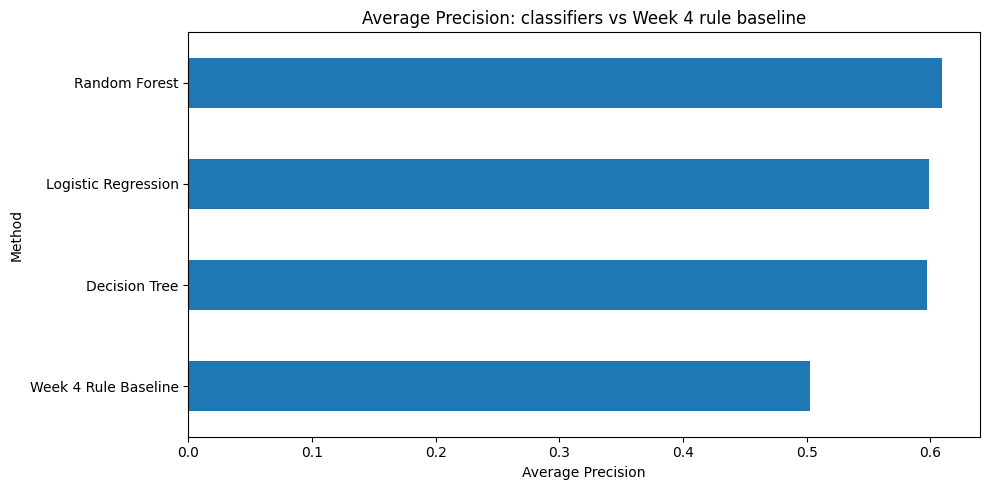

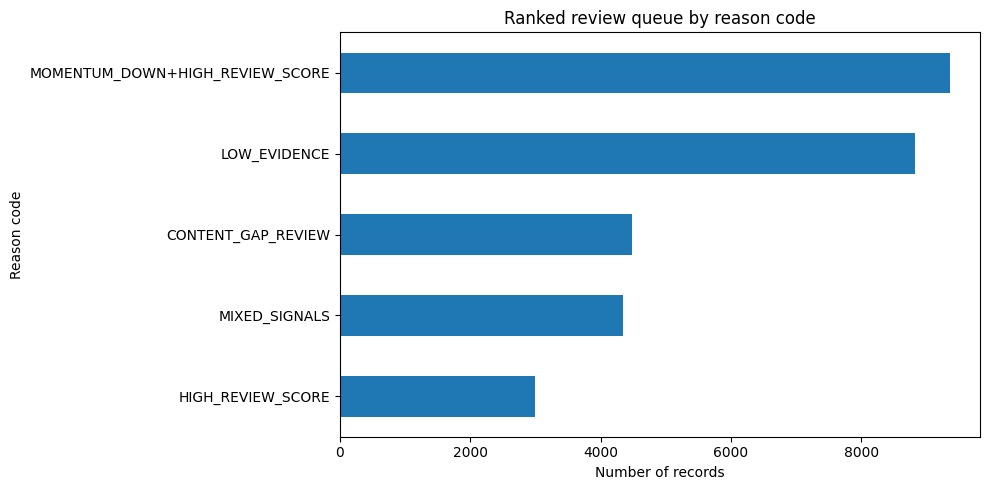

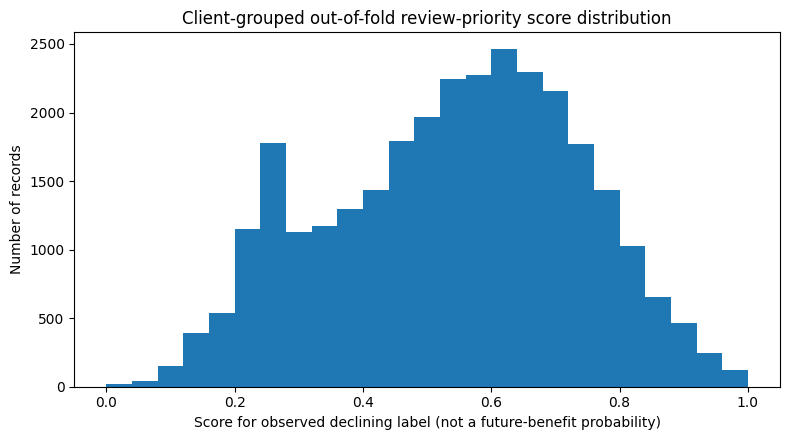

Artifacts written:
- work/figures/capstone_average_precision.png
- work/figures/capstone_reason_codes.png
- work/figures/capstone_priority_score_distribution.png
- work/outputs/capstone_metrics.json
- work/capstone_report.md
- work/outputs/capstone_ranked_review_queue.csv

Reminder: the row-level CSV must remain ignored and must not be committed.


In [8]:

from pathlib import Path
import json
import matplotlib.pyplot as plt

# Keep row-level exports local/ignored by the repository; publish aggregate charts and metrics only.
if repo_root is None:
    repo_root = Path.cwd().resolve()
work_outputs = repo_root / "work" / "outputs"
figures_dir = repo_root / "work" / "figures"
work_outputs.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

comparison_plot = comparison.copy()
fig, ax = plt.subplots(figsize=(10, 5))
comparison_plot["Average Precision"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Average Precision: classifiers vs Week 4 rule baseline")
ax.set_xlabel("Average Precision")
ax.set_ylabel("Method")
fig.tight_layout()
ap_chart_path = figures_dir / "capstone_average_precision.png"
fig.savefig(ap_chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 5))
queue["reason_code"].value_counts().sort_values().plot(kind="barh", ax=ax)
ax.set_title("Ranked review queue by reason code")
ax.set_xlabel("Number of records")
ax.set_ylabel("Reason code")
fig.tight_layout()
reason_chart_path = figures_dir / "capstone_reason_codes.png"
fig.savefig(reason_chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(queue["review_priority_score"], bins=25)
ax.set_title("Client-grouped out-of-fold review-priority score distribution")
ax.set_xlabel("Score for observed declining label (not a future-benefit probability)")
ax.set_ylabel("Number of records")
fig.tight_layout()
score_chart_path = figures_dir / "capstone_priority_score_distribution.png"
fig.savefig(score_chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Row-level queue export is useful locally but must remain gitignored (work/**/*.csv).
queue_export_path = work_outputs / "capstone_ranked_review_queue.csv"
queue.to_csv(queue_export_path, index=False)

metrics_payload = {
    "project": "FlyRank Google Search Ranking & Discoverability Capstone",
    "lane": "Refresh / Content Opportunity Scoring",
    "random_state": RANDOM_STATE,
    "target_definition": "target=1 when trend_direction == 'down' in the supplied snapshot",
    "rows_used": int(len(model_df)),
    "feature_count": int(len(feature_cols)),
    "train_rows": int(len(train_idx)),
    "test_rows": int(len(test_idx)),
    "train_clients": int(len(train_clients)),
    "test_clients": int(len(test_clients)),
    "client_overlap": int(len(train_clients & test_clients)),
    "test_base_rate": float(y_test.mean()),
    "comparison": {
        str(method): {
            str(metric): (None if pd.isna(value) else float(value))
            for metric, value in row.items()
        }
        for method, row in comparison.iterrows()
    },
    "queue_rows": int(len(queue)),
    "queue_score_method": "5-fold client-grouped out-of-fold Logistic Regression scores",
    "limits": [
        "Observed declining-label proxy, not verified future decline",
        "Client-grouped holdout is not time-forward validation",
        "Feature timestamps and operational availability require confirmation",
        "No causal refresh-impact claims",
        "Human review required before action",
    ],
}
metrics_path = work_outputs / "capstone_metrics.json"
metrics_path.write_text(json.dumps(metrics_payload, indent=2), encoding="utf-8")

# Generate a paper-ready Markdown report from current-run values.
best_ap = comparison.loc[["Decision Tree", "Logistic Regression", "Random Forest"], "Average Precision"].idxmax()
best_p50 = comparison.loc[["Decision Tree", "Logistic Regression", "Random Forest"], "Precision@50"].idxmax()
abstract = (
    f"This project asks whether historical content-performance signals can help rank records "
    f"labelled as declining for manual review. It uses the anonymized FlyRank ML Internship starter "
    f"dataset and defines the positive label as trend_direction == 'down'. Three classifiers are "
    f"evaluated against the Week 4 rule baseline on a client-grouped 80/20 holdout. In this run, "
    f"{best_ap} has the highest Average Precision among the classifiers "
    f"({comparison.loc[best_ap, 'Average Precision']:.3f}); "
    f"{best_p50} has the highest Precision@50 among the classifiers "
    f"({comparison.loc[best_p50, 'Precision@50']:.3f}). The ranked output is a human-reviewed "
    f"decision-support queue, not a verified forecast or a causal estimate of refresh benefit."
)

def fmt(value):
    return "Not available" if pd.isna(value) else f"{value:.4f}"

table_lines = [
    "| Method | Precision@10 | Precision@20 | Precision@50 | Precision@100 | ROC-AUC | Average Precision | Brier Score |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
for method, row in comparison.iterrows():
    table_lines.append(
        f"| {method} | {fmt(row['Precision@10'])} | {fmt(row['Precision@20'])} | "
        f"{fmt(row['Precision@50'])} | {fmt(row['Precision@100'])} | {fmt(row['ROC-AUC'])} | "
        f"{fmt(row['Average Precision'])} | {fmt(row['Brier Score'])} |"
    )
paper_md = f"""# Intelligent Content Refresh Prioritization

## Abstract
{abstract}

## 1. Introduction and problem statement
Content teams have limited review capacity and need a consistent way to prioritize pages for investigation. This project evaluates whether historical search-performance signals can rank records carrying an observed declining label. The intended decision is which records should receive manual review first—not whether a page must be refreshed.

## 2. Data
The analysis uses the anonymized FlyRank ML Internship starter dataset (`content_refresh_anonymized.csv`) from the repository's approved starter release. The unit of analysis is a pseudonymized content record. The positive target is `trend_direction == 'down'`; all other accepted labels form the comparison class. Client and content identifiers are used only for grouping, deterministic tie handling, and internal alignment; they are excluded from model features and public recommendation outputs. The capstone reports aggregate results only.

## 3. Methodology
For impressions, clicks, and sessions, the 61–90 day window is reconstructed as the 90-day total minus the latest 30-day and previous 30-day values. Negative or incomplete reconstructions are treated as missing. Features use the reconstructed 61–90 day and previous 30-day windows plus selected content metadata. Target-derived fields, identifiers, latest 30-day metrics, and 90-day totals are excluded from predictors. Imputation, scaling, and one-hot encoding are fitted within sklearn pipelines. The evaluation uses a fixed-seed, client-grouped 80/20 split. Decision Tree, Logistic Regression, and Random Forest are compared with the Week 4 rule baseline on the same held-out rows.

## 4. Results
Test target base rate: **{y_test.mean():.3f}**. Train/test client overlap: **{len(train_clients & test_clients)}**.

{chr(10).join(table_lines)}

![Average Precision comparison](../figures/capstone_average_precision.png)

## 5. Limitations and honest framing
The label is an observed snapshot category, not a future-window outcome. A client-grouped holdout tests generalization to unseen clients but is not time-forward validation. Feature timestamps and operational availability require verification. The analysis is observational and cannot show that refreshing content causes traffic gains or that the model represents Google's ranking algorithm. Scores are ranking aids, not calibrated probabilities of refresh benefit.

## 6. Ranked recommendations
The output queue ranks anonymized records using five-fold client-grouped out-of-fold Logistic Regression scores for the observed declining label. Reason codes connect scores with prior momentum and evidence availability. Low-evidence records should be deferred; high-priority records should receive a human review of intent match, seasonality, technical health, and business value. No publication, deletion, or technical change should be automated.

## 7. Reproducibility
Notebook: `work/notebooks/capstone.ipynb`. Random seed: `{RANDOM_STATE}`. Run from a clean Colab runtime using **Runtime → Run all**. Aggregate metrics are written to `work/outputs/capstone_metrics.json`; charts are written to `work/figures/`. The row-level review queue is a local/ignored export and must not be committed.

## 8. Acknowledgments and data credit
Built on the [FlyRank ML Internship dataset](https://flyrank.ai).
"""
paper_path = repo_root / "work" / "capstone_report.md"
paper_path.write_text(paper_md, encoding="utf-8")

print("Artifacts written:")
for p in [ap_chart_path, reason_chart_path, score_chart_path, metrics_path, paper_path, queue_export_path]:
    print(f"- {p.relative_to(repo_root)}")
print("\nReminder: the row-level CSV must remain ignored and must not be committed.")


## 8. Closing deliverables: demo, social post, employer summary

The closing cell generates the required five-minute demo outline, a concise social-post cut, and a three-sentence employer-facing summary using the current-run results.


In [9]:

print("5-MINUTE DEMO OUTLINE")
print("0:00–0:45 | Problem: content teams need a defensible review-priority queue.")
print("0:45–1:30 | Data and label: anonymized starter data; observed trend_direction == 'down'.")
print("1:30–2:30 | Method: historical-window features, leakage exclusions, client-grouped split.")
print("2:30–3:30 | Results: compare the three classifiers with the Week 4 baseline using the current-run table.")
print("3:30–4:30 | Recommendations: show aggregate reason-code counts and a few anonymous queue rows.")
print("4:30–5:00 | Limits: proxy label, no time-forward test, human review required.")

best_ap_name = comparison.loc[["Decision Tree", "Logistic Regression", "Random Forest"], "Average Precision"].idxmax()
best_ap_value = comparison.loc[best_ap_name, "Average Precision"]
social_post = (
    "I completed a machine-learning capstone on content refresh prioritization using the FlyRank ML Internship dataset. "
    "I compared three classifiers with a rule-based baseline using a client-grouped holdout and built a ranked, human-reviewed "
    "content review queue. The findings are directional decision support—not a claim about Google's algorithm or proof that refreshes cause growth."
)
employer_summary = (
    f"I built a reproducible content-prioritization workflow using historical search and content metadata. "
    f"On a client-grouped holdout, {best_ap_name} achieved the highest Average Precision among the classifiers "
    f"({best_ap_value:.3f}) in this run, with results compared against the Week 4 rule baseline. "
    "The output ranks records for human review; predictor timestamps and time-forward performance remain limitations."
)
print("\nSOCIAL-POST CUT\n", social_post)
print("\n3-SENTENCE EMPLOYER SUMMARY\n", employer_summary)


5-MINUTE DEMO OUTLINE
0:00–0:45 | Problem: content teams need a defensible review-priority queue.
0:45–1:30 | Data and label: anonymized starter data; observed trend_direction == 'down'.
1:30–2:30 | Method: historical-window features, leakage exclusions, client-grouped split.
2:30–3:30 | Results: compare the three classifiers with the Week 4 baseline using the current-run table.
3:30–4:30 | Recommendations: show aggregate reason-code counts and a few anonymous queue rows.
4:30–5:00 | Limits: proxy label, no time-forward test, human review required.

SOCIAL-POST CUT
 I completed a machine-learning capstone on content refresh prioritization using the FlyRank ML Internship dataset. I compared three classifiers with a rule-based baseline using a client-grouped holdout and built a ranked, human-reviewed content review queue. The findings are directional decision support—not a claim about Google's algorithm or proof that refreshes cause growth.

3-SENTENCE EMPLOYER SUMMARY
 I built a reprodu

## Final self-check

Run **Runtime → Run all** in a clean Colab session. Verify the output values against the current run; do not claim that the notebook has been executed successfully until every cell passes.

- [ ] All cells run top to bottom without errors.
- [ ] Week 4 baseline fields and meanings match the Week 4 notebook.
- [ ] Client-grouped split has zero client overlap.
- [ ] Target-derived fields, identifiers, latest 30-day metrics, and 90-day totals are excluded from predictors.
- [ ] Model and baseline use the same held-out records and labels.
- [ ] Metrics are interpreted alongside the held-out base rate.
- [ ] Paper claims are limited to observed, measured, directional decision-support findings.
- [ ] No client-identifying data, credentials, private queries, or raw exports are committed.
- [ ] `work/capstone_report.md` is reviewed and the paper has all required sections.
- [ ] The deployed paper credits the FlyRank ML Internship dataset with a link to https://flyrank.ai.
- [ ] The notebook is committed to `work/notebooks/capstone.ipynb`.
- [ ] `submission/paper_url.txt` contains exactly one line: the direct deployed paper URL.


In [10]:
# FINAL AUTOMATED VALIDATION

required_models = {"Decision Tree", "Logistic Regression", "Random Forest"}
expected_methods = required_models | {"Week 4 Rule Baseline"}
required_metrics = [
    "Precision@10", "Precision@20", "Precision@50", "Precision@100",
    "ROC-AUC", "Average Precision", "Brier Score",
]

assert "comparison" in globals(), "Run Section 3 before the final self-check."
assert set(comparison.index) == expected_methods, "Comparison must include all three classifiers and the Week 4 baseline."
assert all(metric in comparison.columns for metric in required_metrics), "A required metric is missing."
assert len(comparison) == 4

# Classifier metrics must all be finite; baseline P@K can be NA only when fewer than K pages qualify.
for model_name in required_models:
    assert np.isfinite(comparison.loc[model_name, required_metrics].to_numpy(dtype=float)).all(), f"Invalid metrics for {model_name}."
for k in (10, 20, 50, 100):
    value = comparison.loc["Week 4 Rule Baseline", f"Precision@{k}"]
    assert (eligible_count >= k and np.isfinite(value)) or (eligible_count < k and pd.isna(value))
assert np.isfinite(comparison.loc["Week 4 Rule Baseline", ["ROC-AUC", "Average Precision"]].to_numpy(dtype=float)).all()
assert pd.isna(comparison.loc["Week 4 Rule Baseline", "Brier Score"])

assert set(predictions) == required_models
for model_name, scores in predictions.items():
    scores = np.asarray(scores, dtype=float)
    assert len(scores) == len(y_test), f"Prediction count mismatch for {model_name}."
    assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all(), f"Invalid probabilities for {model_name}."

assert train_clients.isdisjoint(test_clients), "Client overlap detected."
assert len(errors) == len(y_test), "Error analysis row count mismatch."
assert set(errors["error_type"].unique()).issubset({"Correct", "False Positive", "False Negative"})
assert (tn + fp + fn + tp) == len(y_test)

print("=" * 58)
print("FINAL NOTEBOOK SELF-CHECK: ALL AUTOMATED CHECKS PASSED")
print("PASS: Three classifiers and Week 4 baseline are compared.")
print("PASS: Required ranking metrics and classifier Brier Scores are valid.")
print("PASS: Baseline unavailable metrics are handled explicitly.")
print("PASS: Predictions align with the held-out test rows.")
print("PASS: No client overlap between train and test.")
print("PASS: Error analysis aligns with the test labels.")
print("MANUAL: Verify historical feature availability and commit the notebook.")
print("=" * 58)

FINAL NOTEBOOK SELF-CHECK: ALL AUTOMATED CHECKS PASSED
PASS: Three classifiers and Week 4 baseline are compared.
PASS: Required ranking metrics and classifier Brier Scores are valid.
PASS: Baseline unavailable metrics are handled explicitly.
PASS: Predictions align with the held-out test rows.
PASS: No client overlap between train and test.
PASS: Error analysis aligns with the test labels.
MANUAL: Verify historical feature availability and commit the notebook.
